# 003 — VAE (Variational Autoencoder) + espacio latente generativo

La diferencia clave:

Un **Autoencoder** aprende a representar puntos concretos:

```text
sonido A → punto A
sonido B → punto B
```

Un **VAE** aprende una **distribución continua de posibilidades**:

```text
        sonidos brillantes

             ○ ○ ○

        ○           ○

    ○                 ○

        sonidos suaves
```

Esto permite **moverse por el espacio latente** y generar sonidos intermedios o nuevos, que no estaban exactamente en los datos originales.

Un Autoencoder aprende a representar puntos concretos.
Un VAE aprende una distribución continua en un espacio latente, permitiendo generar nuevas variaciones a partir de lo aprendido.

Esto permitiría transformar los datos de los gestos táctiles en un espacio latente navegable, donde gestos similares ocupen regiones cercanas y pueden producir nuevas combinaciones sonoras. (QUIZAS Y POR QUE?: Porque el VAE no garantiza por sí solo que “gestos similares queden cerca”. Esa organización depende DE LOS DATOS, EL ENTRENAMIENTO y de COMO ESTE DISEÑADA LA REPRESENTACION. Lo que aporta el VAE es una representación probabilística y continua, que hace posible esa exploración.

## Arquitectura

```text
                 VAE

Audio
  │
  ↓
Encoder
  │
  ↓
 μ , σ
  │
  ↓
 z — espacio latente
  │
  ↓
Decoder
  │
  ↓
Audio generado
```

La parte nueva del VAE es el **sampling**:

```text
z = μ + σ × ruido
```

La red no aprende solamente dónde están los sonidos, sino una **zona de posibilidades sonoras** que podemos explorar y desde la cual podemos generar nuevos sonidos.


Celda 1 — Instalar librerías

En Colab:

In [ ]:
# ==========================================================
# CELDA — Instalar librerías
# ==========================================================

!pip install tensorflow librosa

# TensorFlow → construir y entrenar modelos de IA.
# Librosa → analizar y trabajar con audio.

Celda 2 — Importar



In [ ]:
# ==========================================================
# CELDA — Importar librerías
# ==========================================================

import numpy as np
# NumPy → trabajar con números, vectores y arrays.

import tensorflow as tf
# TensorFlow → construir y entrenar modelos de IA.

from tensorflow.keras import layers, Model
# Keras → crear las capas y modelos de la red neuronal.

from IPython.display import Audio
# Audio → escuchar sonidos directamente en Colab.

import matplotlib.pyplot as plt
# Matplotlib → crear gráficos y visualizar el espacio latente.

Celda 3 — Usamos los sonidos del 002

Si tienes la variable:

sonidos

la reutilizamos.

Comprobamos:

sonidos.shape

Debe salir:

(numero_sonidos, 22050)

In [ ]:
# ==========================================================
# CELDA 3 — Crear dataset de sonidos sintéticos
# ==========================================================


# ----------------------------------------------------------
# 1. PARÁMETROS DEL AUDIO
# ----------------------------------------------------------

sr = 22050
# Sample rate: 22.050 muestras por segundo.

duration = 1
# Cada sonido dura 1 segundo.


# ----------------------------------------------------------
# 2. EJE TEMPORAL
# ----------------------------------------------------------

t = np.linspace(
    0,
    duration,
    sr,
    endpoint=False
)

# Crea los puntos de tiempo del sonido.
# endpoint=False evita incluir el último punto (1 segundo).


# ----------------------------------------------------------
# 3. FUNCIÓN DE SÍNTESIS
# ----------------------------------------------------------

def crear_sonido(freq, armonico):

    # freq = frecuencia fundamental.
    # armonico = múltiplo de la frecuencia fundamental
    # que modifica el timbre.


    # Frecuencia fundamental:
    # genera un tono sinusoidal.

    sonido = np.sin(
        2 * np.pi * freq * t
    )


    # Armónico:
    # agrega otra frecuencia relacionada con la fundamental.
    # Su amplitud es 0.3 (30%).

    sonido += 0.3 * np.sin(
        2 * np.pi * (freq * armonico) * t
    )


    return sonido


# ----------------------------------------------------------
# 4. GENERAR LOS SONIDOS
# ----------------------------------------------------------

sonidos = []


for f in range(100, 1000, 50):
    # Frecuencias desde 100 hasta 950 Hz.


    for h in range(1, 6):
        # Cinco relaciones armónicas: 1, 2, 3, 4 y 5.


        s = crear_sonido(
            f,
            h
        )

        # Genera un sonido para cada combinación
        # de frecuencia y armónico.


        sonidos.append(s)
        # Agrega el sonido al dataset.


# ----------------------------------------------------------
# 5. CONVERTIR A ARRAY
# ----------------------------------------------------------

sonidos = np.array(
    sonidos,
    dtype="float32"
)

# Convertimos la lista en un array de NumPy.
# float32 reduce el tamaño de los datos y es adecuado para TensorFlow.


# ----------------------------------------------------------
# 6. NORMALIZAR
# ----------------------------------------------------------

sonidos = sonidos / np.max(
    np.abs(sonidos)
)

# Ajusta la amplitud de todos los sonidos
# a una escala común entre -1 y 1.


# ----------------------------------------------------------
# 7. COMPROBAR DATASET
# ----------------------------------------------------------

print("Dataset:")
print(sonidos.shape)

# Resultado esperado:
# (90, 22050)
#
# 90 sonidos × 22.050 muestras por sonido.

Dataset:
(90, 22050)


Debe salir algo parecido a:

Dataset:
(90, 22050)

Ahora ya :

90 sonidos
    |
    ↓
cada uno con 22050 muestras

y ahora continuar con el VAE.

La diferencia con el 002 es que ahora estos sonidos no buscan solo reconstruirse; el VAE intentará aprender una geometría continua del espacio sonoro.

Sí. Ahora viene la parte central: crear el VAE.

En el 002 tenía:

Audio → Encoder → z → Decoder → Audio

Ahora agrego una diferencia:

Audio
 ↓
Encoder
 ↓
μ (media) + σ (variación)
 ↓
z (muestra del espacio latente)
 ↓
Decoder
 ↓
Audio

In [ ]:
# ==========================================================
# CELDA 4 — Encoder VAE
# ==========================================================

from tensorflow.keras import layers, Model
import tensorflow as tf


# ----------------------------------------------------------
# 1. DIMENSIONES
# ----------------------------------------------------------

input_dim = sonidos.shape[1]
# Cantidad de muestras que tiene cada sonido.

latent_dim = 2
# El espacio latente tendrá 2 dimensiones:
# Z1 y Z2.


# ----------------------------------------------------------
# 2. ENTRADA
# ----------------------------------------------------------

entrada = layers.Input(
    shape=(input_dim,)
)

# Recibe un sonido completo.


# ----------------------------------------------------------
# 3. COMPRESIÓN
# ----------------------------------------------------------

x = layers.Dense(
    128,
    activation="relu"
)(entrada)

# Reduce el sonido a 128 valores.


# ----------------------------------------------------------
# 4. MEDIA DEL ESPACIO LATENTE
# ----------------------------------------------------------

z_mean = layers.Dense(
    latent_dim,
    name="z_mean"
)(x)

# Calcula la posición media del sonido
# dentro del espacio latente.


# ----------------------------------------------------------
# 5. VARIACIÓN DEL ESPACIO LATENTE
# ----------------------------------------------------------

z_log_var = layers.Dense(
    latent_dim,
    name="z_log_var"
)(x)

# Calcula cuánto puede variar esa posición.


# ----------------------------------------------------------
# 6. CREAR ENCODER
# ----------------------------------------------------------

encoder = Model(
    entrada,
    [z_mean, z_log_var],
    name="encoder"
)

# El Encoder ahora entrega:
#
# sonido → μ + variación → espacio latente


# ----------------------------------------------------------
# 7. VER EL MODELO
# ----------------------------------------------------------

encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 22050)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 128)       │  2,822,528 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        258 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        258 │ dense_6[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,823,044 (10.77 MB)

 Trainable params: 2,823,044 (10.77 MB)

 Non-trainable params: 0 (0.00 B)

La diferencia con el Autoencoder 002 es esta:

En el Autoencoder:

audio → [0.3, -0.5]

un punto fijo.

En el VAE:

audio → distribución
          |
          ↓
      z_mean + z_log_var
          |
          ↓
      punto latente z

Celda 5 — Sampling.

In [ ]:
# ==========================================================
# CELDA 5 — Sampling del espacio latente
# ==========================================================


# ----------------------------------------------------------
# 1. FUNCIÓN DE SAMPLING
# ----------------------------------------------------------

def sampling(args):

    # Recibimos:
    # z_mean = posición media
    # z_log_var = variación de esa posición

    z_mean, z_log_var = args


    # ------------------------------------------------------
    # 2. CREAR RUIDO ALEATORIO
    # ------------------------------------------------------

    epsilon = tf.random.normal(
        shape=tf.shape(z_mean)
    )

    # Crea una pequeña variación aleatoria.
    # Esto permite que el VAE explore distintas posiciones
    # alrededor de la media.


    # ------------------------------------------------------
    # 3. CREAR EL PUNTO LATENTE
    # ------------------------------------------------------

    return (
        z_mean +
        tf.exp(0.5 * z_log_var)
        * epsilon
    )

    # Combina:
    # posición media + variación + ruido
    #
    # Resultado → un punto z del espacio latente.


# ----------------------------------------------------------
# 4. APLICAR SAMPLING
# ----------------------------------------------------------

z = layers.Lambda(
    sampling,
    name="espacio_latente"
)(
    [z_mean, z_log_var]
)

# Ahora tenemos el punto latente que será enviado
# al Decoder.


# ----------------------------------------------------------
# 5. COMPROBAR RESULTADO
# ----------------------------------------------------------

print(z)

# Muestra el tensor que representa
# el espacio latente generado.

<KerasTensor shape=(None, 2), dtype=float32, sparse=False, ragged=False, name=keras_tensor_20>


Si funciona se verá algo parecido:

KerasTensor shape=(None,2)

Aquí ocurre la parte clave del VAE:

z = μ + σ · ruido

La red ya no aprende solamente puntos, aprende una región continua de posibilidades.

Después de esta celda hacemos:

Celda 6 — Decoder VAE

que será:

z (2 dimensiones)
        ↓
     Dense 128
        ↓
     Dense 22050
        ↓
      audio

y luego se entrena el VAE completo.

Celda 6 — Decoder del VAE.

Este toma el punto latente z (2 dimensiones) y lo transforma nuevamente en una onda sonora de 22050 muestras.

In [ ]:
# ==========================================================
# CELDA 6 — Decoder VAE
# ==========================================================


# ----------------------------------------------------------
# 1. ENTRADA DEL DECODER
# ----------------------------------------------------------

latent_input = layers.Input(
    shape=(latent_dim,),
    name="latent_input"
)

# Recibe un punto del espacio latente:
# Z1 y Z2.


# ----------------------------------------------------------
# 2. EXPANDIR EL ESPACIO LATENTE
# ----------------------------------------------------------

x = layers.Dense(
    128,
    activation="relu"
)(latent_input)

# Expande los 2 valores latentes
# hacia una representación más grande.


# ----------------------------------------------------------
# 3. RECONSTRUIR EL AUDIO
# ----------------------------------------------------------

salida_audio = layers.Dense(
    input_dim,
    activation="tanh"
)(x)

# Convierte la representación en un sonido.
# tanh mantiene los valores dentro de -1 y 1.


# ----------------------------------------------------------
# 4. CREAR EL DECODER
# ----------------------------------------------------------

decoder = Model(
    latent_input,
    salida_audio,
    name="decoder"
)

# Ahora tenemos:
#
# Z1, Z2 → Decoder → audio


# ----------------------------------------------------------
# 5. VER EL MODELO
# ----------------------------------------------------------

decoder.summary()

# Muestra las capas y parámetros del Decoder.

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ latent_input (InputLayer)       │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 22050)          │     2,844,450 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,844,834 (10.85 MB)

 Trainable params: 2,844,834 (10.85 MB)

 Non-trainable params: 0 (0.00 B)

Este decoder se ve muy parecido al del Autoencoder anterior porque la parte de decodificar puede tener la misma arquitectura.

La diferencia está en cómo se construye el espacio latente.

Autoencoder 002

Tenías:

Audio
 ↓
Encoder
 ↓
z = [z1,z2]
 ↓
Decoder
 ↓
Audio

El encoder aprende:

"Este sonido corresponde a este punto"

Ejemplo:

sonido A → z = (0.3, -0.2)
sonido B → z = (1.1, 0.5)

El mapa puede quedar irregular:

A        B


      C


D

Puede haber zonas vacías donde no se sabe qué significa moverse.

VAE 003

Ahora tengo:

Audio
 ↓
Encoder
 ↓
z_mean + z_log_var
 ↓
Sampling
 ↓
z
 ↓
Decoder
 ↓
Audio

La red aprende:

"Este sonido pertenece a una región probable del espacio"

No guarda solamente un punto.

Ejemplo:

sonido A:

     centro = (0.3,-0.2)
     variación = pequeña zona alrededor


sonido B:

     centro = (1.1,0.5)
     variación = otra zona

El espacio queda más continuo:

     A A A

  A       B B

       C C C

D D

Entonces se puede navegar entre regiones y obtener sonidos intermedios.


Autoencoder:

gesto
 ↓
punto fijo
 ↓
sonido

VAE:

gesto
 ↓
posición dentro de un campo sonoro
 ↓
posibles sonidos

Sobre la tabla:

Autoencoder 002:

Latente:
(None,2)

VAE:

z_mean:
(None,2)

z_log_var:
(None,2)

z:
(None,2)

La diferencia aparece antes del decoder.

El decoder recibe igual:

[z1,z2]

pero esos valores vienen de un espacio con estructura probabilística.

En una frase:

El Autoencoder aprende un mapa; el VAE aprende un territorio.

Y esa diferencia es justamente la que conecta con tu idea de espacios latentes continuos

unir todo el VAE y entrenarlo.

Hasta ahora tengo piezas separadas:

Encoder
    ↓
z_mean + z_log_var
    ↓
Sampling
    ↓
z
    ↓
Decoder

Pero todavía no existe el modelo completo.

Celda 7 — Construir el VAE completo

In [ ]:
# ==========================================================
# CELDA 7 — Decoder VAE
# ==========================================================

latent_dim = 2
# El espacio latente tiene 2 dimensiones: Z1 y Z2.


latent_input = layers.Input(
    shape=(latent_dim,),
    name="latent_input"
)
# El Decoder recibe Z1 y Z2.


x = layers.Dense(
    128,
    activation="relu"
)(latent_input)
# Expande los 2 valores latentes.


salida_audio = layers.Dense(
    input_dim,
    activation="tanh"
)(x)
# Reconstruye el audio.


decoder = Model(
    latent_input,
    salida_audio,
    name="decoder"
)
# Crea el Decoder independiente.


decoder.summary()
# Muestra la arquitectura del Decoder.

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ latent_input (InputLayer)       │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 22050)          │     2,844,450 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,844,834 (10.85 MB)

 Trainable params: 2,844,834 (10.85 MB)

 Non-trainable params: 0 (0.00 B)

Celda 8 — Función de pérdida VAE

A diferencia del Autoencoder, no basta con:

error de reconstrucción

Ahora tenemos:

pérdida total =
reconstrucción
+
organización del espacio latente

La solución más limpia es crear una clase VAE con el train_step personalizado.

In [ ]:
# ==========================================================
# CELDA 8 — Clase VAE y función de pérdida
# ==========================================================

#Esta clase define cómo aprende el VAE:
# reconstruye el sonido y mantiene organizado el espacio latente.

# ----------------------------------------------------------
# 1. CREAR LA CLASE VAE
# ----------------------------------------------------------

class VAE(Model):

    def __init__(self, encoder, decoder):

        super(VAE, self).__init__()

        self.encoder = encoder
        self.decoder = decoder

        # El VAE está formado por:
        # Encoder + Sampling + Decoder.


    # ------------------------------------------------------
    # 2. CÓMO APRENDE EL VAE
    # ------------------------------------------------------

    def train_step(self, data):

        if isinstance(data, tuple):
            data = data[0]

        # Tomamos el sonido original.


        # --------------------------------------------------
        # 3. ENCODER
        # --------------------------------------------------

        with tf.GradientTape() as tape:

            z_mean, z_log_var = self.encoder(data)

            # El Encoder calcula:
            # z_mean = posición media
            # z_log_var = variación


            # ------------------------------------------------
            # 4. SAMPLING
            # ------------------------------------------------

            z = sampling(
                [z_mean, z_log_var]
            )

            # Generamos un punto del espacio latente.


            # ------------------------------------------------
            # 5. DECODER
            # ------------------------------------------------

            reconstruction = self.decoder(z)

            # El Decoder intenta reconstruir
            # el sonido original.


            # ------------------------------------------------
            # 6. PÉRDIDA DE RECONSTRUCCIÓN
            # ------------------------------------------------

            reconstruction_loss = tf.reduce_mean(
                tf.square(
                    data - reconstruction
                )
            )

            # Mide cuánto se parece
            # el sonido reconstruido al original.
            #
            # Menor pérdida = mejor reconstrucción.


            # ------------------------------------------------
            # 7. PÉRDIDA KL
            # ------------------------------------------------

            kl_loss = -0.5 * tf.reduce_mean(
                1 +
                z_log_var -
                tf.square(z_mean) -
                tf.exp(z_log_var)
            )

            # La pérdida KL ayuda a mantener
            # el espacio latente continuo y organizado.


            # ------------------------------------------------
            # 8. PÉRDIDA TOTAL
            # ------------------------------------------------

            total_loss = (
                reconstruction_loss +
                kl_loss
            )

            # El VAE intenta optimizar las dos cosas:
            #
            # reconstrucción + espacio latente


        # --------------------------------------------------
        # 9. ACTUALIZAR LA RED
        # --------------------------------------------------

        grads = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(
                grads,
                self.trainable_weights
            )
        )

        # Ajusta los pesos de la red
        # para que aprenda.


        # --------------------------------------------------
        # 10. MOSTRAR LAS PÉRDIDAS
        # --------------------------------------------------

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss
        }

        # Devuelve las tres pérdidas para poder observar
        # cómo aprende el VAE.

celda9

In [ ]:
# ==========================================================
# CELDA 9 — Crear y compilar VAE
# ==========================================================

# Creamos el VAE completo:
# Encoder + Sampling + Decoder.

vae = VAE(
    encoder,
    decoder
)


# ----------------------------------------------------------
# COMPILAR
# ----------------------------------------------------------

vae.compile(
    optimizer="adam"
)

# Adam ajusta los pesos de la red
# para que aprenda durante el entrenamiento.

# Adam = algoritmo que ajusta los pesos de la red
# para reducir la pérdida y mejorar el aprendizaje.
# optimizadores más utilizados en redes neuronales


# ----------------------------------------------------------
# VER MODELO
# ----------------------------------------------------------

vae.summary()

# Muestra la estructura del VAE completo.

Model: "vae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Functional)            │ ((None, 2), (None, 2)) │     2,823,044 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 22050)          │     2,844,834 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,667,878 (21.62 MB)

 Trainable params: 5,667,878 (21.62 MB)

 Non-trainable params: 0 (0.00 B)

Adam trabaja con números: los pesos de la red.
https://keras.io/api/optimizers/adam/

Por ejemplo, una neurona puede tener:

peso = 0.35

La red produce un error. Adam calcula cuánto debe cambiar ese peso:

0.35 → 0.34

y hace esto con millones de pesos durante el entrenamiento.

En este VAE:

sonido
  ↓
red neuronal
  ↓
error
  ↓
Adam calcula ajustes
  ↓
cambia los pesos
  ↓
vuelve a probar

Así, después de muchas iteraciones, los números internos de la red van quedando organizados para reconstruir mejor los sonidos y aprender el espacio latente.

In [ ]:
# ==========================================================
# CELDA 10 — Entrenamiento del VAE
# ==========================================================

historia = vae.fit(
    sonidos,
    epochs=100,
    batch_size=16
)

# El VAE aprende a:
# 1. Reconstruir los sonidos.
# 2. Organizar un espacio latente continuo.
#
# epochs = 100 recorridos por el dataset.
# batch_size = procesa 16 sonidos por grupo.

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step - kl_loss: 5.0660 - loss: 5.4178 - reconstruction_loss: 0.3519
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - kl_loss: 0.1357 - loss: 0.4918 - reconstruction_loss: 0.3561
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - kl_loss: 1.6870 - loss: 2.0469 - reconstruction_loss: 0.3599
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - kl_loss: 2.5492 - loss: 2.8980 - reconstruction_loss: 0.3488
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - kl_loss: 2.6458 - loss: 2.9866 - reconstruction_loss: 0.3409
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - kl_loss: 7.2806 - loss: 7.6338 - reconstruction_loss: 0.3532
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - kl_loss: 3.3758 - loss: 3.7133 - reconstruction_loss: 0.3375
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - kl_loss: 0.0847 - loss: 0.4214 - reconstruction_loss: 0.3367
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - kl_loss: 0.6773 - loss: 1.0142 - reconstruc

ahora el entrenamiento realmente contiene:

Reconstrucción:
"que el sonido vuelva parecido"

+

KL:
"que el espacio latente sea continuo y ordenado"

Es decir:

Autoencoder:
aprende puntos

VAE:
aprende un territorio sonoro

Después de entrenar, el siguiente paso será muy bonito: sacar el decoder del VAE y hacer:

(z1,z2)
   ↓
decoder
   ↓
sonido nuevo

y comparar con el Autoencoder 002. Ahí vas a escuchar la diferencia.

posición en el espacio latente
              ↓
             (z1,z2)
              ↓
          Decoder VAE
              ↓
          sonido nuevo
Celda 11 — Generar sonido desde una coordenada latente

In [ ]:
# ==========================================================
# CELDA 11 — Explorar espacio latente VAE
# ==========================================================


# ----------------------------------------------------------
# 1. ELEGIR UNA POSICIÓN
# ----------------------------------------------------------

z_nuevo = np.array([
    [0.0, 0.0]
])

# Elegimos una posición dentro del espacio latente:
# Z1 = 0.0
# Z2 = 0.0


# ----------------------------------------------------------
# 2. GENERAR SONIDO
# ----------------------------------------------------------

sonido_generado = decoder.predict(
    z_nuevo
)

# El Decoder transforma esa posición
# en un sonido generado.


# ----------------------------------------------------------
# 3. ESCUCHAR
# ----------------------------------------------------------

Audio(
    sonido_generado[0],
    rate=sr
)

# Escuchamos el sonido producido
# desde esa posición del espacio latente.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


Celda 12 — Dibujar el espacio latente del VAE

para ver dónde quedaron organizados los sonidos:

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


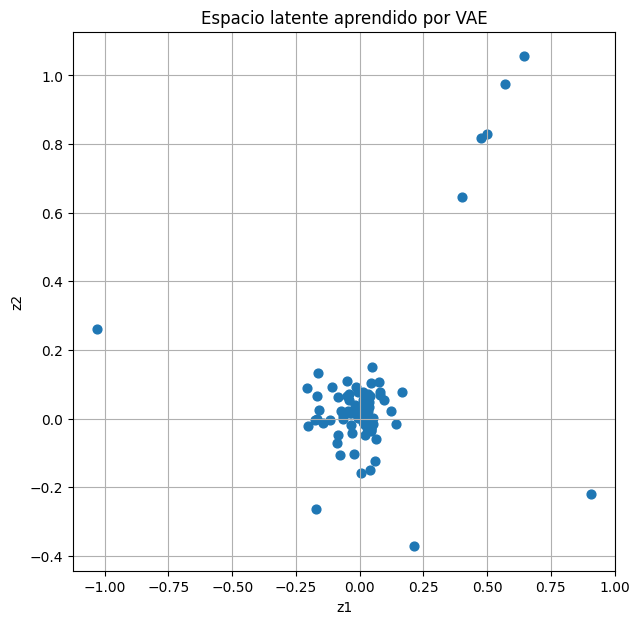

In [ ]:
# ==========================================================
# CELDA 12 — Visualizar espacio latente VAE
# ==========================================================


# ----------------------------------------------------------
# 1. OBTENER LAS COORDENADAS LATENTES
# ----------------------------------------------------------

z_mean, z_log_var = encoder.predict(
    sonidos
)

# El Encoder transforma cada sonido
# en una posición dentro del espacio latente.
#
# Usamos z_mean para visualizar
# la posición de cada sonido.


# ----------------------------------------------------------
# 2. CREAR EL GRÁFICO
# ----------------------------------------------------------

plt.figure(
    figsize=(7,7)
)


# ----------------------------------------------------------
# 3. DIBUJAR LOS SONIDOS
# ----------------------------------------------------------

plt.scatter(
    z_mean[:,0],
    z_mean[:,1],
    s=40
)

# Cada punto representa un sonido.
# Su posición corresponde a Z1 y Z2.


# ----------------------------------------------------------
# 4. NOMBRAR LOS EJES
# ----------------------------------------------------------

plt.xlabel("z1")
plt.ylabel("z2")


# ----------------------------------------------------------
# 5. TÍTULO
# ----------------------------------------------------------

plt.title(
    "Espacio latente aprendido por VAE"
)


# ----------------------------------------------------------
# 6. CUADRÍCULA
# ----------------------------------------------------------

plt.grid()


# ----------------------------------------------------------
# 7. MOSTRAR
# ----------------------------------------------------------

plt.show()

# Ahora podemos observar visualmente
# cómo el VAE organiza los sonidos.

Cada punto representa un sonido del dataset.

La diferencia con el Autoencoder 002 es que ahora se espera que el espacio sea más continuo y compacto, porque la pérdida KL ( KL → ordena el espacio latente
Reconstrucción → conserva la información del sonido) obliga a la red a organizar las regiones latentes.

Después de esta celda :

Celda 13 — Generar una cuadrícula completa del espacio latente

Por ejemplo:

(-2,-2) → sonido
(-1,-2) → sonido
( 0,-2) → sonido
( 1,-2) → sonido
...

y se escuchará cómo cambia al desplazarse por el "territorio sonoro". Ese paso ya es muy cercano a la idea de navegación de un espacio latente.

Celda 13 — Navegar el espacio latente con controles

In [ ]:
# ==========================================================
# CELDA 13 — Explorar el espacio latente VAE
# ==========================================================

from ipywidgets import interact
from IPython.display import display, Audio


# ----------------------------------------------------------
# 1. CREAR CONTROLES
# ----------------------------------------------------------

@interact(
    z1=(-3.0, 3.0, 0.1),
    z2=(-3.0, 3.0, 0.1)
)

# Creamos dos controles para movernos
# por el espacio latente:
#
# z1 = posición horizontal
# z2 = posición vertical


# ----------------------------------------------------------
# 2. FUNCIÓN DE EXPLORACIÓN
# ----------------------------------------------------------

def explorar_VAE(
    z1=0.0,
    z2=0.0
):

    # Cada combinación de z1 y z2
    # representa una posición diferente.


    # ------------------------------------------------------
    # 3. CREAR PUNTO LATENTE
    # ------------------------------------------------------

    punto = np.array([
        [z1, z2]
    ])

    # Convertimos la posición
    # en un formato que entiende el Decoder.


    # ------------------------------------------------------
    # 4. GENERAR SONIDO
    # ------------------------------------------------------

    sonido = decoder.predict(
        punto
    )

    # El Decoder transforma la posición
    # en un sonido generado.


    # ------------------------------------------------------
    # 5. ESCUCHAR
    # ------------------------------------------------------

    display(
        Audio(
            sonido[0],
            rate=sr
        )
    )

    # Escuchamos el resultado.

interactive(children=(FloatSlider(value=0.0, description='z1', max=3.0, min=-3.0), FloatSlider(value=0.0, desc…

## ¿Por qué el VAE cambia tan poco?

Es normal en este primer experimento.

### 1. Dataset pequeño

Solo tenemos **90 sonidos sintéticos**:

```text
90 sonidos
   ↓
  VAE
   ↓
espacio latente
```

Hay poca diversidad para aprender.

### 2. Espacio latente pequeño

Tenemos:

```python
latent_dim = 2
```

Esto sirve para **visualizar**, pero es limitado para representar sonidos complejos.

```text
2D → visualizar y explorar
8D / 16D / 32D → representar sonidos más complejos
```

### 3. Estamos explorando demasiado lejos

El slider va de:

```text
-3 → 3
```

pero el VAE quizás aprendió una zona mucho más pequeña.

Podemos probar:

```python
@interact(
    z1=(-1.0, 1.0, 0.05),
    z2=(-1.0, 1.0, 0.05)
)
```

### 4. El Decoder genera directamente una onda

Ahora tenemos:

```text
espacio latente
      ↓
    Decoder
      ↓
onda de audio
```

Todavía no estamos controlando directamente:

* frecuencia
* envolvente
* espectro
* granularidad

Más adelante, para TmaqT, podemos hacer:

```text
gesto
  ↓
espacio latente
  ↓
parámetros de síntesis
  ↓
FM / granular / síntesis híbrida
  ↓
sonido
```

Una prueba interesante:

Podemos recorrer una línea del espacio latente:

```python
for x in np.linspace(-1, 1, 10):

    punto = np.array([
        [x, 0]
    ])

    sonido = decoder.predict(
        punto
    )

    display(
        Audio(
            sonido[0],
            rate=sr
        )
    )
```

Así escuchamos cómo cambia el sonido al desplazarnos por una **línea dentro del espacio latente**.

Si cambia muy poco, significa que este primer VAE aprendió un espacio **muy comprimido y simple**.


In [ ]:
# ==========================================================
# CELDA 13 — Explorar espacio latente VAE (ajustado)
# ==========================================================

from ipywidgets import interact
from IPython.display import display, Audio


# ----------------------------------------------------------
# 1. CREAR CONTROLES
# ----------------------------------------------------------

@interact(
    z1=(-1.0, 1.0, 0.05),
    z2=(-1.0, 1.0, 0.05)
)

# Limitamos el recorrido porque el VAE
# aprendió una zona pequeña del espacio latente.


# ----------------------------------------------------------
# 2. FUNCIÓN DE EXPLORACIÓN
# ----------------------------------------------------------

def explorar_VAE(
    z1=0.0,
    z2=0.0
):

    # Cada combinación de z1 y z2
    # representa una posición del espacio latente.


    # ------------------------------------------------------
    # 3. CREAR PUNTO LATENTE
    # ------------------------------------------------------

    punto = np.array([
        [z1, z2]
    ])

    # Convertimos la posición en un formato
    # que puede recibir el Decoder.


    # ------------------------------------------------------
    # 4. GENERAR SONIDO
    # ------------------------------------------------------

    sonido = decoder.predict(
        punto,
        verbose=0
    )

    # El Decoder transforma la posición
    # en un sonido.


    # ------------------------------------------------------
    # 5. NORMALIZAR VOLUMEN
    # ------------------------------------------------------

    sonido = sonido[0]

    sonido = sonido / np.max(
        np.abs(sonido)
    )

    # Ajustamos el volumen para que
    # cada sonido se escuche con una amplitud similar.


    # ------------------------------------------------------
    # 6. ESCUCHAR
    # ------------------------------------------------------

    display(
        Audio(
            sonido,
            rate=sr
        )
    )

    # Reproduce el sonido generado.

interactive(children=(FloatSlider(value=0.0, description='z1', max=1.0, min=-1.0, step=0.05), FloatSlider(valu…

Ahora una versión donde veo dónde estoy dentro del espacio latente mientras escucho.

La idea:

        z2

        ↑

   ● ● ● ●
 ● ● ● ● ● ●
 ● ●   X ● ●     ← mi posición actual
 ● ● ● ● ● ●
   ● ● ● ●


--------------→ z1

dos cosas:

La nube de puntos que aprendió el VAE (z_mean)
El punto actual que muevo con sliders
Celda 14 — Navegador visual + sonido VAE

In [ ]:
# ==========================================================
# CELDA 14 — Navegación visual del espacio latente
# ==========================================================

from ipywidgets import interact
from IPython.display import display, Audio
import matplotlib.pyplot as plt


# ----------------------------------------------------------
# 1. OBTENER LAS POSICIONES APRENDIDAS
# ----------------------------------------------------------

z_mean, z_log_var = encoder.predict(
    sonidos,
    verbose=0
)

# Cada sonido tiene una posición dentro
# del espacio latente aprendido.


# ----------------------------------------------------------
# 2. CREAR CONTROLES
# ----------------------------------------------------------

@interact(
    z1=(-1.0, 1.0, 0.05),
    z2=(-1.0, 1.0, 0.05)
)

# z1 = posición horizontal
# z2 = posición vertical


# ----------------------------------------------------------
# 3. FUNCIÓN DE NAVEGACIÓN
# ----------------------------------------------------------

def navegar_latente(
    z1=0.0,
    z2=0.0
):

    # ------------------------------------------------------
    # 4. DIBUJAR EL ESPACIO LATENTE
    # ------------------------------------------------------

    plt.figure(
        figsize=(5,5)
    )

    # Dibujamos los sonidos aprendidos.

    plt.scatter(
        z_mean[:,0],
        z_mean[:,1],
        s=40
    )


    # ------------------------------------------------------
    # 5. MOSTRAR POSICIÓN ACTUAL
    # ------------------------------------------------------

    plt.scatter(
        z1,
        z2,
        s=200,
        marker="X"
    )

    # La X muestra dónde estamos navegando.


    plt.xlabel("z1")
    plt.ylabel("z2")

    plt.title(
        "Exploración del espacio latente VAE"
    )

    plt.grid()

    plt.show()


    # ------------------------------------------------------
    # 6. CREAR PUNTO LATENTE
    # ------------------------------------------------------

    punto = np.array([
        [z1, z2]
    ])

    # Convertimos la posición actual
    # en un punto que recibe el Decoder.


    # ------------------------------------------------------
    # 7. GENERAR SONIDO
    # ------------------------------------------------------

    sonido = decoder.predict(
        punto,
        verbose=0
    )

    # El Decoder transforma la posición
    # en sonido.


    # ------------------------------------------------------
    # 8. NORMALIZAR VOLUMEN
    # ------------------------------------------------------

    sonido = sonido[0]

    sonido = sonido / np.max(
        np.abs(sonido)
    )

    # Mantiene un volumen adecuado
    # para la escucha.


    # ------------------------------------------------------
    # 9. ESCUCHAR
    # ------------------------------------------------------

    display(
        Audio(
            sonido,
            rate=sr
        )
    )

    # Audio() crea el reproductor.
    # display() lo muestra en Colab para poder escucharlo.
    # rate=sr indica la velocidad de reproducción.

interactive(children=(FloatSlider(value=0.0, description='z1', max=1.0, min=-1.0, step=0.05), FloatSlider(valu…

## ¿Por qué el sonido cambia poco?

El gráfico funciona, pero el sonido cambia poco. **No es una falla: muestra una limitación de este primer experimento.**

El VAE sí aprende:

✓ una organización del espacio latente

Pero todavía aprende:

✗ poca variación sonora

### ¿Por qué?

**Dataset muy simple**

Los sonidos están construidos principalmente con:

```text
seno + armónico
```

Hay poca diversidad tímbrica.

**Pocos datos**

Tenemos solamente:

```text
90 sonidos
```

**Decoder muy simple**

El Decoder tiene que reconstruir directamente:

```text
22050 muestras
      ↓
onda de audio
```

Por eso aprende una solución bastante conservadora.


Lo importante

Conceptualmente, el objetivo del **003** sí se consiguió:

```text
sonidos
   ↓
  VAE
   ↓
espacio latente
   ↓
exploración
   ↓
 Decoder
   ↓
 audio generado
```

El siguiente desafío será aumentar la **diversidad sonora** y hacer que el espacio latente controle **procesos de síntesis**, no solamente una onda de audio.
